In [1]:
import pandas as pd 
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer


from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

In [2]:
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "developement" else Path.cwd()
DATA_PATH = (RACINE / "data" / "train.csv") if (RACINE / "data" / "train.csv").exists() else (RACINE / "train.csv")
initial_train_set = pd.read_csv(DATA_PATH, sep=",")


In [3]:
# Cible de fréquence
initial_train_set["sinistre"] = (initial_train_set["nombre_sinistres"] > 0).astype(int)
print(initial_train_set["nombre_sinistres"].value_counts().sort_index())

# Jeu complet : Random Forest / gradient boosting
num_rf = ["bonus", "anciennete_vehicule", "din_vehicule", "anciennete_permis1",
          "age_conducteur1", "cylindre_vehicule", "age_conducteur2", "anciennete_permis2",
          "prix_vehicule", "poids_vehicule", "vitesse_vehicule",
          "debut_vente_vehicule", "fin_vente_vehicule"]
cat_rf = ["type_contrat", "type_vehicule", "essence_vehicule", "conducteur2"]

# # Jeu réduit : régression logistique (un représentant par groupe redondant)
# num_glm = ["bonus", "anciennete_vehicule", "din_vehicule", "anciennete_permis1"]
# cat_glm = ["type_contrat", "type_vehicule", "essence_vehicule", "conducteur2"]

X = initial_train_set[num_rf + cat_rf]
y = initial_train_set["sinistre"]

nombre_sinistres
0    47083
1     2917
Name: count, dtype: int64


In [4]:
# 1. On isole le test 
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=42)

# 2. On coupe le reste en train 
X_train, X_dev, y_train, y_dev = train_test_split(
    X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=42)

for nom, Xs, ys in [("Train", X_train, y_train), ("Dev", X_dev, y_dev), ("Test", X_test, y_test)]:
    print(f"{nom:5s} : {Xs.shape[0]:6d} lignes ({Xs.shape[0] / len(X):.0%}) | taux sinistre {ys.mean():.2%}")

Train :  36000 lignes (72%) | taux sinistre 5.83%
Dev   :   9000 lignes (18%) | taux sinistre 5.83%
Test  :   5000 lignes (10%) | taux sinistre 5.84%


In [5]:
def manquants_structurels(X):
    """Sans second conducteur : âge et permis à 0, pas une médiane."""
    X = X.copy()
    sans_c2 = X["conducteur2"] == "No"
    X.loc[sans_c2, ["age_conducteur2", "anciennete_permis2"]] = 0
    return X

colonnes = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), num_rf), 
    ("cat", Pipeline([
        ("imputation", SimpleImputer(strategy="constant", fill_value="Inconnu")),
        ("encodage", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                   min_frequency=30, drop="if_binary",
                                   sparse_output=False)),
    ]), cat_rf),
])

preprocesseur = Pipeline([
    ("structurels", FunctionTransformer(manquants_structurels, feature_names_out="one-to-one")),
    ("colonnes", colonnes),
])

- Tranformation de données - Encodage - Gestion des inférences à valeurs vides

In [6]:
Xtr = preprocesseur.fit_transform(X_train)   # fit sur le train uniquement
Xdv = preprocesseur.transform(X_dev)
Xte = preprocesseur.transform(X_test)

print(f"Train {Xtr.shape} | Dev {Xdv.shape} | Test {Xte.shape}")
print(f"NaN : {np.isnan(Xtr).sum()}, {np.isnan(Xdv).sum()}, {np.isnan(Xte).sum()}")
print(list(preprocesseur.get_feature_names_out()))

Train (36000, 23) | Dev (9000, 23) | Test (5000, 23)
NaN : 0, 0, 0
['num__bonus', 'num__anciennete_vehicule', 'num__din_vehicule', 'num__anciennete_permis1', 'num__age_conducteur1', 'num__cylindre_vehicule', 'num__age_conducteur2', 'num__anciennete_permis2', 'num__prix_vehicule', 'num__poids_vehicule', 'num__vitesse_vehicule', 'num__debut_vente_vehicule', 'num__fin_vente_vehicule', 'num__missingindicator_anciennete_vehicule', 'cat__type_contrat_Maxi', 'cat__type_contrat_Median1', 'cat__type_contrat_Median2', 'cat__type_contrat_Mini', 'cat__type_vehicule_Tourism', 'cat__essence_vehicule_Diesel', 'cat__essence_vehicule_Gasoline', 'cat__essence_vehicule_Hybrid', 'cat__conducteur2_Yes']


# Entrainement 

In [7]:
def evaluer(modele, X, y, nom=""):
    p = modele.predict_proba(X)[:, 1]
    return {"jeu": nom,
            "ROC_AUC": roc_auc_score(y, p),
            "PR_AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p),
            "proba_moy": p.mean()}

# Référence : prédit le taux moyen pour tout le monde
naif = Pipeline([("prep", preprocesseur), ("modele", DummyClassifier(strategy="prior"))])
naif.fit(X_train, y_train)

# Random Forest
rf = Pipeline([
    ("prep", preprocesseur),
    ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=100,
                                      max_features="sqrt", n_jobs=-1, random_state=42)),
])
rf.fit(X_train, y_train)

res = pd.DataFrame([
    evaluer(naif, X_dev, y_dev, "Naïf - dev"),
    evaluer(rf, X_train, y_train, "RF - train"),
    evaluer(rf, X_dev, y_dev, "RF - dev"),
]).round(4)
display(res)

,jeu,ROC_AUC,PR_AUC,Brier,proba_moy
0,Naïf - dev,0.5000,0.0583,0.0549,0.0583
1,RF - train,0.7524,0.1611,0.0528,0.0584
2,RF - dev,0.6656,0.0994,0.0539,0.0585


In [8]:
resultats = []
for leaf in [20, 50, 100, 200, 400]:
    for mf in ["sqrt", 0.5]:
        rf.set_params(modele__min_samples_leaf=leaf, modele__max_features=mf)
        rf.fit(X_train, y_train)
        r_tr = evaluer(rf, X_train, y_train)
        r_dv = evaluer(rf, X_dev, y_dev)
        resultats.append({"min_leaf": leaf, "max_features": mf,
                          "AUC_train": r_tr["ROC_AUC"], "AUC_dev": r_dv["ROC_AUC"],
                          "ecart": r_tr["ROC_AUC"] - r_dv["ROC_AUC"],
                          "PR_AUC_dev": r_dv["PR_AUC"], "Brier_dev": r_dv["Brier"]})

grille = pd.DataFrame(resultats).sort_values("AUC_dev", ascending=False).round(4)
display(grille)

,min_leaf,max_features,AUC_train,AUC_dev,ecart,PR_AUC_dev,Brier_dev
2,50,sqrt,0.8183,0.6665,0.1517,0.1008,0.0539
4,100,sqrt,0.7524,0.6656,0.0868,0.0994,0.0539
6,200,sqrt,0.7066,0.6643,0.0423,0.0977,0.0539
8,400,sqrt,0.6784,0.6626,0.0158,0.0981,0.0540
9,400,0.5,0.6897,0.6621,0.0276,0.0968,0.0540
5,100,0.5,0.7794,0.6621,0.1173,0.1003,0.0539
7,200,0.5,0.7243,0.6616,0.0626,0.0974,0.0540
0,20,sqrt,0.9169,0.6612,0.2557,0.1013,0.0540
3,50,0.5,0.8507,0.6584,0.1922,0.1006,0.0540
1,20,0.5,0.9416,0.6516,0.2900,0.1020,0.0541


KeyError: 'ROC_AUC'

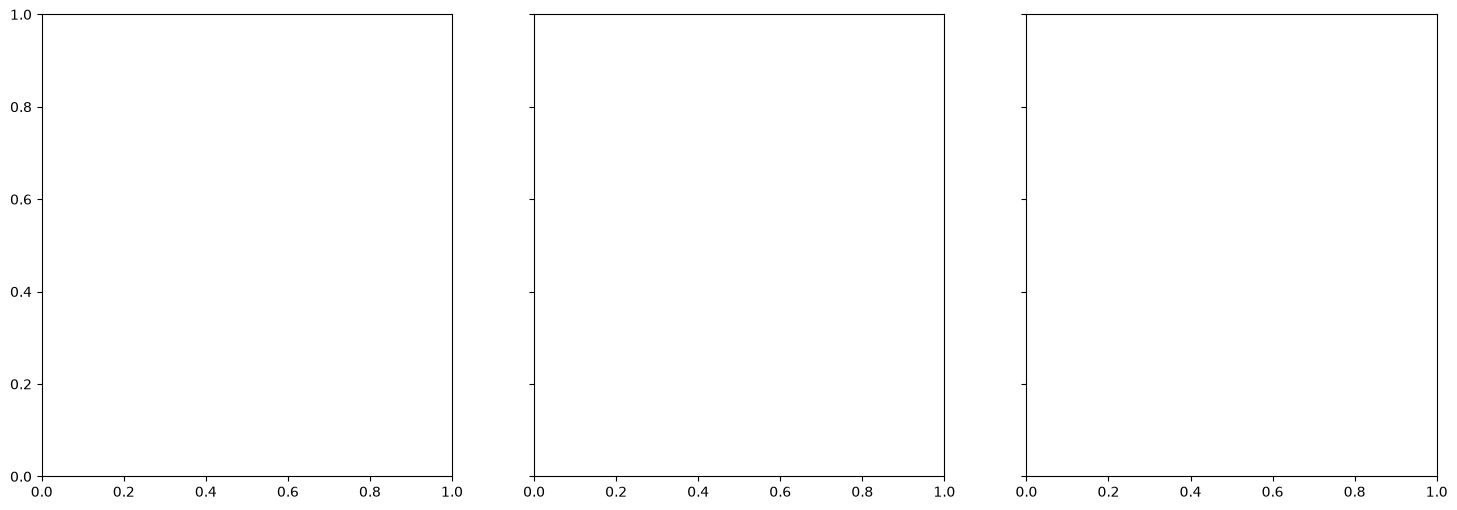

In [9]:
metriques = [("ROC_AUC", "plus haut = mieux"),
             ("PR_AUC", "plus haut = mieux"),
             ("Brier", "plus bas = mieux")]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
ordre = grille.sort_values("ROC_AUC")   # meilleure config en haut

for ax, (m, sens) in zip(axes, metriques):
    ax.barh(ordre["config"], ordre[m], color="tab:blue")
    ax.axvline(base[m], color="red", ls="--", lw=1.5, label=f"Naïf : {base[m]:.4f}")

    # zoom sur la zone utile, sinon les écarts sont invisibles
    vals = list(ordre[m]) + [base[m]]
    marge = (max(vals) - min(vals)) * 0.15
    ax.set_xlim(min(vals) - marge, max(vals) + marge)

    for y_pos, v in enumerate(ordre[m]):
        ax.text(v, y_pos, f" {v:.4f}", va="center", fontsize=8)
    ax.set_title(f"{m} ({sens})")
    ax.legend(loc="lower right")

# écart train/dev en surimpression sur le ROC AUC
axes[0].scatter(ordre["AUC_train"], ordre["config"], color="orange", zorder=3, label="AUC train")
axes[0].legend(loc="lower right")

plt.suptitle("Random Forest : métriques sur le dev selon les hyperparamètres", fontsize=13)
plt.tight_layout(); plt.show()

In [10]:
rf.set_params(modele__min_samples_leaf=200, modele__max_features="sqrt")
rf.fit(X_train, y_train)

p_dev = rf.predict_proba(X_dev)[:, 1]
lift = pd.DataFrame({"proba": p_dev, "reel": y_dev.values})
lift["decile"] = pd.qcut(lift["proba"].rank(method="first"), 10, labels=range(1, 11))

tab = lift.groupby("decile", observed=True).agg(proba_moy=("proba", "mean"),
                                                taux_reel=("reel", "mean"),
                                                nb_sinistres=("reel", "sum"),
                                                effectif=("reel", "size"))
tab["lift"] = tab["taux_reel"] / y_dev.mean()
display(tab.round(3))

,proba_moy,taux_reel,nb_sinistres,effectif,lift
decile,,,,,
1,0.015,0.011,10,900,0.190
2,0.025,0.021,19,900,0.362
3,0.035,0.027,24,900,0.457
4,0.045,0.032,29,900,0.552
5,0.055,0.061,55,900,1.048
6,0.064,0.081,73,900,1.390
7,0.072,0.069,62,900,1.181
8,0.079,0.077,69,900,1.314
9,0.088,0.092,83,900,1.581


## Interprétation finale du modèle retenu

**Modèle** : Random Forest, 300 arbres, `min_samples_leaf=200`, `max_features="sqrt"`.

### 1. Objectif et choix des métriques

L'objectif est d'estimer, pour chaque client, la probabilité d'avoir au moins un sinistre dans l'année. Avec seulement 5,8 % de sinistrés, l'accuracy n'est pas pertinente : un modèle prédisant « aucun sinistre » pour tous atteindrait 94,2 % sans rien apprendre. Le modèle a donc été évalué sur deux capacités :

- **classer** les clients selon leur risque (ROC AUC, PR AUC, lift) ;
- fournir des **probabilités fiables**, utilisables pour la tarification (score de Brier, calibration).

### 2. Choix des hyperparamètres

Dix configurations ont été comparées sur le jeu de développement. Leurs ROC AUC sont très proches (0,652 à 0,667), des écarts non significatifs. Le choix s'est donc fait sur la **capacité de généralisation** : `min_samples_leaf=200` réduit l'écart entre entraînement et développement de 0,15 à 0,04, pour une perte d'AUC négligeable (0,002). Le modèle retenu est moins sensible au bruit des données d'entraînement, et donc plus fiable sur de nouveaux clients.

### 3. Performances (jeu de développement)

| Métrique | Modèle naïf | Random Forest |
|---|---|---|
| ROC AUC | 0,500 | 0,664 |
| PR AUC | 0,058 | 0,098 |
| Brier | 0,0549 | 0,0539 |
| Probabilité moyenne prédite | 5,8 % | 5,9 % |

- **Capacité de classement** : face à une paire (un sinistré, un non-sinistré), le modèle attribue le risque le plus élevé au bon client dans environ deux cas sur trois. C'est un niveau satisfaisant en assurance automobile, où la survenance d'un sinistre dépend largement de facteurs aléatoires absents des données.
- **Qualité des probabilités** : le gain sur le Brier est modeste (2 %), ce qui est attendu pour un événement rare. La probabilité moyenne prédite correspond au taux réel : le modèle ne surestime ni ne sous-estime le risque global.

### 4. Segmentation du risque (lift)

| Décile | Probabilité prédite | Taux réel | Sinistres | Lift |
|---|---|---|---|---|
| 1 (moins risqués) | 1,5 % | 1,1 % | 10 | 0,19 |
| 5 | 5,5 % | 6,1 % | 55 | 1,05 |
| 10 (plus risqués) | 10,7 % | 11,2 % | 101 | 1,92 |

- Les 10 % de clients jugés les moins risqués ont un taux de sinistre de **1,1 %**, soit 5 fois moins que la moyenne.
- Les 10 % jugés les plus risqués ont un taux de **11,2 %**, soit près de 2 fois plus que la moyenne.
- Le risque varie donc **d'un facteur 10** entre les deux extrémités.
- Les 30 % de clients les plus risqués concentrent **48 % des sinistres**.
- Dans chaque décile, la probabilité prédite est proche du taux observé : le modèle est **bien calibré**.

### 5. Intérêt métier

Le modèle permet une tarification différenciée : les profils peu risqués peuvent se voir proposer une prime de fréquence nettement inférieure à la moyenne, et les profils risqués une prime ajustée à leur sinistralité. L'assureur peut ainsi rester compétitif sur les bons profils sans dégrader son équilibre technique.

### 6. Limites

- Le pouvoir prédictif reste **modéré** (AUC de 0,66) : une part importante du risque relève du hasard et de facteurs non observés (kilométrage, comportement de conduite, zone de circulation précise).
- Ces résultats sont mesurés sur le **jeu de développement**, qui a servi à choisir les hyperparamètres. Ils peuvent être légèrement optimistes.
- Le modèle ne couvre que la **fréquence**. La prime pure nécessitera aussi un modèle de **coût moyen**, dont le signal s'est révélé faible en analyse bivariée.

### 7. Étapes suivantes

1. **Importance des variables** : identifier les facteurs qui pilotent la prédiction et les confronter à l'analyse bivariée.
2. **Évaluation finale sur le jeu de test**, réalisée une seule fois avec la configuration figée, pour obtenir une mesure non biaisée des performances.

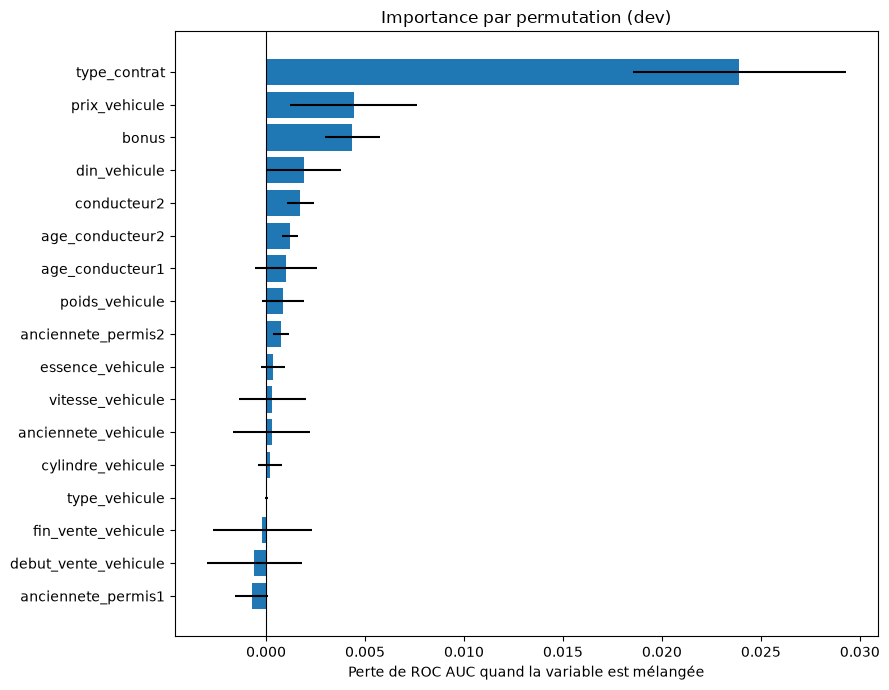

,variable,perte_AUC,ecart_type
13,type_contrat,0.0239,0.0054
8,prix_vehicule,0.0044,0.0032
0,bonus,0.0044,0.0014
2,din_vehicule,0.0019,0.0019
16,conducteur2,0.0017,0.0007
6,age_conducteur2,0.0012,0.0004
4,age_conducteur1,0.0010,0.0016
9,poids_vehicule,0.0009,0.0011
7,anciennete_permis2,0.0008,0.0004
15,essence_vehicule,0.0004,0.0006


In [11]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_dev, y_dev, scoring="roc_auc",
                              n_repeats=10, random_state=42, n_jobs=-1)

imp_perm = pd.DataFrame({"variable": X_dev.columns,
                         "perte_AUC": perm.importances_mean,
                         "ecart_type": perm.importances_std}
                        ).sort_values("perte_AUC", ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(imp_perm["variable"], imp_perm["perte_AUC"], xerr=imp_perm["ecart_type"], color="tab:blue")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Perte de ROC AUC quand la variable est mélangée")
ax.set_title("Importance par permutation (dev)")
plt.tight_layout(); plt.show()

display(imp_perm.sort_values("perte_AUC", ascending=False).round(4))

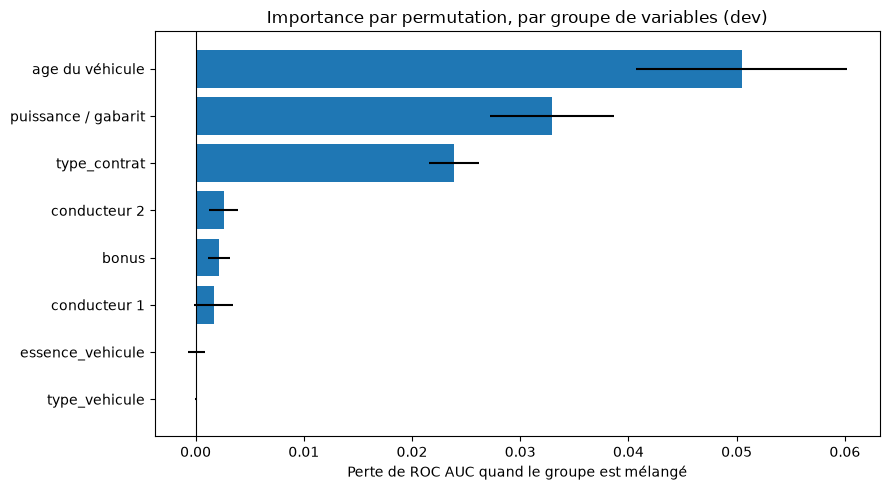

,groupe,perte_AUC,ecart_type
1,age du véhicule,0.0505,0.0097
2,puissance / gabarit,0.0329,0.0057
0,type_contrat,0.0239,0.0023
4,conducteur 2,0.0026,0.0013
3,bonus,0.0022,0.0010
5,conducteur 1,0.0017,0.0018
6,essence_vehicule,0.0001,0.0008
7,type_vehicule,0.0000,0.0001


In [12]:
from sklearn.metrics import roc_auc_score

groupes = {
    "type_contrat": ["type_contrat"],
    "age du véhicule": ["anciennete_vehicule", "debut_vente_vehicule", "fin_vente_vehicule"],
    "puissance / gabarit": ["prix_vehicule", "din_vehicule", "poids_vehicule",
                            "vitesse_vehicule", "cylindre_vehicule"],
    "bonus": ["bonus"],
    "conducteur 2": ["conducteur2", "age_conducteur2", "anciennete_permis2"],
    "conducteur 1": ["age_conducteur1", "anciennete_permis1"],
    "essence_vehicule": ["essence_vehicule"],
    "type_vehicule": ["type_vehicule"],
}

auc_ref = roc_auc_score(y_dev, rf.predict_proba(X_dev)[:, 1])
rng = np.random.default_rng(42)
res = []

for nom, cols in groupes.items():
    pertes = []
    for _ in range(10):
        Xp = X_dev.copy()
        idx = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[idx]       # même permutation pour tout le groupe
        pertes.append(auc_ref - roc_auc_score(y_dev, rf.predict_proba(Xp)[:, 1]))
    res.append({"groupe": nom, "perte_AUC": np.mean(pertes), "ecart_type": np.std(pertes)})

imp_g = pd.DataFrame(res).sort_values("perte_AUC")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp_g["groupe"], imp_g["perte_AUC"], xerr=imp_g["ecart_type"], color="tab:blue")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Perte de ROC AUC quand le groupe est mélangé")
ax.set_title("Importance par permutation, par groupe de variables (dev)")
plt.tight_layout(); plt.show()
display(imp_g.sort_values("perte_AUC", ascending=False).round(4))

In [13]:
def construire_preprocesseur(num, cat):
    def structurels(X):
        X = X.copy()
        if "age_conducteur2" in X.columns:
            sans_c2 = X["conducteur2"] == "No"
            X.loc[sans_c2, ["age_conducteur2", "anciennete_permis2"]] = 0
        return X

    colonnes = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), num),
        ("cat", Pipeline([
            ("imputation", SimpleImputer(strategy="constant", fill_value="Inconnu")),
            ("encodage", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                                       drop="if_binary", sparse_output=False)),
        ]), cat),
    ])
    return Pipeline([("structurels", FunctionTransformer(structurels, feature_names_out="one-to-one")),
                     ("colonnes", colonnes)])

def tester(num, cat, nom):
    modele = Pipeline([
        ("prep", construire_preprocesseur(num, cat)),
        ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=200,
                                          max_features="sqrt", n_jobs=-1, random_state=42)),
    ])
    modele.fit(X_train[num + cat], y_train)
    r = evaluer(modele, X_dev[num + cat], y_dev, nom)
    r["nb_variables"] = len(num + cat)
    return r

cat_reduit = ["type_contrat", "conducteur2"]
num_sans_c1 = [c for c in num_rf if c not in ["age_conducteur1", "anciennete_permis1"]]

comparaison = pd.DataFrame([
    tester(num_rf, cat_rf, "Complet"),
    tester(num_rf, cat_reduit, "Sans essence ni type_vehicule"),
    tester(num_sans_c1, cat_reduit, "Sans essence, type_vehicule, conducteur 1"),
]).round(4)
display(comparaison)

,jeu,ROC_AUC,PR_AUC,Brier,proba_moy,nb_variables
0,Complet,0.6643,0.0977,0.0539,0.0586,17
1,Sans essence ni type_vehicule,0.6629,0.0976,0.0540,0.0586,15
2,"Sans essence, type_vehicule, conducteur 1",0.6611,0.0961,0.0540,0.0587,13


Le retrait de essence_vehicule et type_vehicule n’entraîne qu’une perte d’AUC négligeable (0,001) : leur effet observé en analyse bivariée est entièrement capté par l’âge et la puissance du véhicule. Les variables du conducteur principal sont conservées, leur retrait dégradant la performance au-delà du seuil retenu. Le modèle final utilise 15 variables.

- Entrainement final 

In [14]:
num_final = num_rf
cat_final = ["type_contrat", "conducteur2"]
cols_final = num_final + cat_final

X_final = pd.concat([X_train, X_dev])[cols_final]
y_final = pd.concat([y_train, y_dev])

rf_final = Pipeline([
    ("prep", construire_preprocesseur(num_final, cat_final)),
    ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=200,
                                      max_features="sqrt", n_jobs=-1, random_state=42)),
])
rf_final.fit(X_final, y_final)

naif_final = Pipeline([("prep", construire_preprocesseur(num_final, cat_final)),
                       ("modele", DummyClassifier(strategy="prior"))])
naif_final.fit(X_final, y_final)

res_test = pd.DataFrame([
    evaluer(naif_final, X_test[cols_final], y_test, "Naïf - test"),
    evaluer(rf_final, X_test[cols_final], y_test, "RF - test"),
]).round(4)
display(res_test)

,jeu,ROC_AUC,PR_AUC,Brier,proba_moy
0,Naïf - test,0.5000,0.0584,0.0550,0.0583
1,RF - test,0.6285,0.0852,0.0544,0.0588


In [ ]:
p_test = rf_final.predict_proba(X_test[cols_final])[:, 1]
lift_t = pd.DataFrame({"proba": p_test, "reel": y_test.values})
lift_t["decile"] = pd.qcut(lift_t["proba"].rank(method="first"), 10, labels=range(1, 11))

tab_t = lift_t.groupby("decile", observed=True).agg(proba_moy=("proba", "mean"),
                                                    taux_reel=("reel", "mean"),
                                                    nb_sinistres=("reel", "sum"),
                                                    effectif=("reel", "size"))
tab_t["lift"] = tab_t["taux_reel"] / y_test.mean()
display(tab_t.round(3))

top30 = tab_t.loc[[8, 9, 10], "nb_sinistres"].sum() / tab_t["nb_sinistres"].sum()
print(f"Part des sinistres dans les 30 % les plus risqués : {top30:.1%}")

,proba_moy,taux_reel,nb_sinistres,effectif,lift
decile,,,,,
1,0.014,0.022,11,500,0.377
2,0.025,0.024,12,500,0.411
3,0.034,0.040,20,500,0.685
4,0.045,0.032,16,500,0.548
5,0.055,0.068,34,500,1.164
6,0.065,0.066,33,500,1.130
7,0.072,0.078,39,500,1.336
8,0.079,0.080,40,500,1.370
9,0.089,0.074,37,500,1.267


Part des sinistres dans les 30 % les plus risqués : 43.5%


In [18]:
import sys
import pickle
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "developement" else Path.cwd()
if str(RACINE / "inference_test") not in sys.path:
    sys.path.insert(0, str(RACINE / "inference_test"))

from preparation import construire_preprocesseur

rf_final = Pipeline([
    ("prep", construire_preprocesseur(num_final, cat_final)),
    ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=200,
                                      max_features="sqrt", n_jobs=-1, random_state=42)),
])
rf_final.fit(X_final, y_final)

MODELE_DIR = RACINE / "models"
MODELE_DIR.mkdir(exist_ok=True)
with open(MODELE_DIR / "rf_proba_model.pkl", "wb") as f:
    pickle.dump(rf_final, f)
